1. Bank Account Race Condition

In [ ]:
import threading
import time

Simulasi tanpa Lock

Pada percobaan pertama, saldo diakses oleh beberapa thread secara bersamaan tanpa menggunakan Lock. Setiap thread melakukan operasi tarik Rp1 lalu setor Rp1 sebanyak 10.000 kali.

In [ ]:
saldo = 1_000_000

def transaksi_tanpa_lock():
    global saldo
    
    for _ in range(10_000):
        # Tarik Rp1
        temp = saldo
        time.sleep(0)  # memberi kesempatan thread lain berjalan
        saldo = temp - 1
        
        # Setor Rp1
        temp = saldo
        time.sleep(0)
        saldo = temp + 1

threads = []

for _ in range(10):
    t = threading.Thread(target=transaksi_tanpa_lock)
    threads.append(t)
    t.start()

for t in threads:
    t.join()

print("Saldo akhir tanpa Lock:", saldo)

Secara teori, saldo akhir seharusnya tetap Rp1.000.000 karena setiap transaksi melakukan tarik Rp1 kemudian setor kembali Rp1. Namun, karena beberapa thread mengakses dan mengubah variabel saldo secara bersamaan tanpa pengamanan, dapat terjadi race condition. Akibatnya, beberapa perubahan saldo bisa saling menimpa sehingga saldo akhir dapat berbeda dari saldo awal.

time.sleep(0) digunakan untuk memberikan kesempatan kepada thread lain berjalan sehingga kondisi race lebih mudah terlihat pada percobaan.

Menggunakan threading.Lock()

Sekarang transaksi yang sama dilakukan menggunakan Lock. Lock memastikan hanya satu thread yang dapat mengakses bagian transaksi pada satu waktu.

In [3]:
saldo = 1_000_000
lock = threading.Lock()

def transaksi_dengan_lock():
    global saldo
    
    for _ in range(10_000):
        with lock:
            saldo -= 1
            saldo += 1

threads = []

for _ in range(10):
    t = threading.Thread(target=transaksi_dengan_lock)
    threads.append(t)
    t.start()

for t in threads:
    t.join()

print("Saldo akhir dengan Lock:", saldo)

Saldo akhir dengan Lock: 1000000


Dengan menggunakan threading.Lock(), bagian ketika saldo ditarik dan disetor menjadi critical section. Hanya satu thread yang dapat menjalankan bagian tersebut dalam satu waktu. Oleh karena itu, operasi tarik dan setor tidak saling bertabrakan dengan thread lain.

Karena setiap thread melakukan 10.000 kali transaksi dan terdapat 10 thread, seluruh transaksi tetap menghasilkan perubahan bersih sebesar nol. Jadi, saldo akhir tetap:

Rp1.000.000

2. Producer-Consumer dengan Banyak Consumer

Pada percobaan ini digunakan satu producer dan tiga consumer yang berjalan secara bersamaan. Queue digunakan agar pertukaran data antar-thread lebih aman.

In [4]:
import threading
import queue
import time

q = queue.Queue()

def producer():
    for i in range(15):
        item = f"Data-{i+1}"
        q.put(item)
        print(f"Producer menghasilkan: {item}")
        time.sleep(0.1)

    # Mengirim sinyal berhenti untuk 3 consumer
    for _ in range(3):
        q.put(None)

    print("Producer selesai.")

def consumer(nama):
    while True:
        item = q.get()

        if item is None:
            q.task_done()
            print(f"{nama} berhenti.")
            break

        print(f"{nama} memproses: {item}")
        time.sleep(0.2)

        q.task_done()

producer_thread = threading.Thread(target=producer)

consumer_threads = [
    threading.Thread(target=consumer, args=("Consumer-1",)),
    threading.Thread(target=consumer, args=("Consumer-2",)),
    threading.Thread(target=consumer, args=("Consumer-3",))
]

producer_thread.start()

for t in consumer_threads:
    t.start()

producer_thread.join()

# Menunggu semua item dalam queue selesai diproses
q.join()

for t in consumer_threads:
    t.join()

print("Semua consumer telah berhenti dengan baik.")

Producer menghasilkan: Data-1
Consumer-1 memproses: Data-1
Producer menghasilkan: Data-2
Consumer-2 memproses: Data-2
Producer menghasilkan: Data-3
Consumer-3 memproses: Data-3
Producer menghasilkan: Data-4Consumer-2 memproses: Data-4

Producer menghasilkan: Data-5
Consumer-1 memproses: Data-5
Producer menghasilkan: Data-6
Consumer-2 memproses: Data-6
Producer menghasilkan: Data-7Consumer-3 memproses: Data-7

Producer menghasilkan: Data-8
Consumer-1 memproses: Data-8
Producer menghasilkan: Data-9
Consumer-2 memproses: Data-9
Producer menghasilkan: Data-10Consumer-3 memproses: Data-10

Producer menghasilkan: Data-11
Consumer-1 memproses: Data-11
Producer menghasilkan: Data-12
Consumer-2 memproses: Data-12
Producer menghasilkan: Data-13Consumer-3 memproses: Data-13

Producer menghasilkan: Data-14
Consumer-1 memproses: Data-14
Producer menghasilkan: Data-15
Consumer-2 memproses: Data-15
Producer selesai.Consumer-3 berhenti.
Consumer-1 berhenti.

Consumer-2 berhenti.
Semua consumer telah b

Pada program tersebut terdapat satu producer yang menghasilkan 15 data dan memasukkannya ke dalam Queue. Tiga consumer mengambil data dari queue secara bersamaan dan memprosesnya.

Hal penting pada program ini adalah penggunaan None sebagai sinyal berhenti. Karena terdapat tiga consumer, producer harus memasukkan tiga None, masing-masing untuk satu consumer.

Jika hanya dimasukkan satu None, hanya satu consumer yang akan menerima sinyal berhenti. Dua consumer lainnya masih menunggu data sehingga program dapat terus berjalan dan tidak berhenti dengan baik.

q.task_done() digunakan untuk memberi tahu queue bahwa item yang diambil sudah selesai diproses, sedangkan q.join() digunakan untuk menunggu sampai seluruh item dalam queue selesai.


3. Eksperimen ThreadPoolExecutor

Pada eksperimen ini jumlah file dibuat menjadi 50 file, kemudian dibandingkan waktu eksekusi dengan:

- max_workers = 2
- max_workers = 4
- max_workers = 8
- max_workers = 16

In [5]:
import os

folder = "data_threading"

os.makedirs(folder, exist_ok=True)

for i in range(50):
    with open(os.path.join(folder, f"file_{i+1}.txt"), "w") as f:
        f.write("Ini adalah data percobaan untuk ThreadPoolExecutor.\n" * 100)

print("50 file berhasil dibuat.")

50 file berhasil dibuat.


In [7]:
def process_file(filename):
    path = os.path.join(folder, filename)
    
    with open(path, "r") as f:
        data = f.read()
    
    # Simulasi pekerjaan I/O
    time.sleep(0.05)
    
    return len(data)

In [8]:
from concurrent.futures import ThreadPoolExecutor
import time

files = os.listdir(folder)

workers_list = [2, 4, 8, 16]
execution_times = []

for workers in workers_list:
    start_time = time.perf_counter()

    with ThreadPoolExecutor(max_workers=workers) as executor:
        results = list(executor.map(process_file, files))

    end_time = time.perf_counter()

    execution_time = end_time - start_time
    execution_times.append(execution_time)

    print(f"max_workers = {workers}")
    print(f"Waktu eksekusi = {execution_time:.4f} detik")
    print()

max_workers = 2
Waktu eksekusi = 1.3462 detik

max_workers = 4
Waktu eksekusi = 0.6842 detik

max_workers = 8
Waktu eksekusi = 0.3629 detik

max_workers = 16
Waktu eksekusi = 0.2091 detik



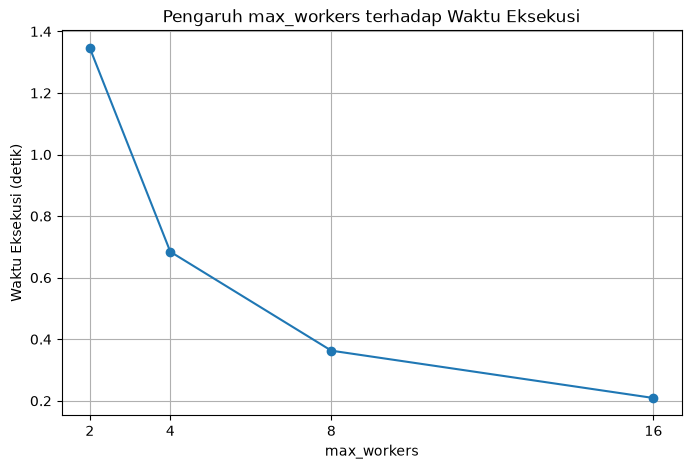

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    workers_list,
    execution_times,
    marker="o"
)

plt.xlabel("max_workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.title("Pengaruh max_workers terhadap Waktu Eksekusi")
plt.xticks(workers_list)
plt.grid(True)

plt.show()

Analisis hasil

Berdasarkan eksperimen, penambahan jumlah max_workers pada awalnya dapat mempercepat proses karena beberapa file dapat diproses secara bersamaan. Misalnya, penggunaan 4 worker dapat menyelesaikan pekerjaan lebih cepat dibandingkan 2 worker.

Namun, menambah jumlah worker tidak selalu membuat proses semakin cepat. Setelah jumlah worker tertentu, peningkatan performa dapat semakin kecil. Hal ini terjadi karena komputer memiliki sumber daya yang terbatas. Terlalu banyak thread juga dapat menimbulkan overhead karena sistem harus mengatur dan menjadwalkan lebih banyak thread.

Selain itu, proses pembacaan file juga bergantung pada kecepatan perangkat penyimpanan. Jika jumlah thread sudah cukup banyak, penambahan thread berikutnya tidak memberikan peningkatan yang signifikan.